<a href="https://colab.research.google.com/github/utpalakshi/asfai/blob/main/Segmentation(U_Net%2Cswish).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 1 — Segmentation

## 1. Dataset Preparation
## 2. Pre-processing
## 3. U-Net
## 4. Results


## 1. Dataset preparation

## 1.1 Extracting datasets from drive

In [ ]:
#Extracting datasets from google drive
# give access for all
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile
import os

# Path to the main ISIC zip file identified in Google Drive
main_zip_path = "/content/drive/MyDrive/ISIC-20260827T135459Z-1-001.zip"
extract_root = "/content/ISIC_dataset_root"
os.makedirs(extract_root, exist_ok=True)

print(f"Extracting {main_zip_path} to {extract_root}...")
with zipfile.ZipFile(main_zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_root)

print("Extraction complete.")
# Verify contents of the extracted directory
!ls -R {extract_root}

Extracting /content/drive/MyDrive/ISIC-20260827T135459Z-1-001.zip to /content/ISIC_dataset_root...
Extraction complete.
/content/ISIC_dataset_root:
ISIC

/content/ISIC_dataset_root/ISIC:
ISBI2016_ISIC_Part1_Training_Data.zip
ISBI2016_ISIC_Part1_Training_GroundTruth.zip
ISBI2016_ISIC_Part3_Training_GroundTruth.csv


With the main zip extracted, we can now reference the `ISBI2016_ISIC_Part1_Training_Data.zip` and `ISBI2016_ISIC_Part1_Training_GroundTruth.zip` files from within the `ISIC_dataset_root`.

## 1.2 Check whether they are accessible

In [ ]:
# Checks whether the datasets are accessible within the extracted directory
!find "/content/ISIC_dataset_root" -type f | grep -i "ISBI"

/content/ISIC_dataset_root/ISIC/ISBI2016_ISIC_Part1_Training_GroundTruth.zip
/content/ISIC_dataset_root/ISIC/ISBI2016_ISIC_Part3_Training_GroundTruth.csv
/content/ISIC_dataset_root/ISIC/ISBI2016_ISIC_Part1_Training_Data.zip


## 1.3 Copying datasets into local colab storage(lesion and segmented image)

In [ ]:
# 1.3 Copying datasets into local Colab storage

# Create local storage folder
!mkdir -p /content/ISIC

# Define paths to the extracted zip files within the root directory
data_zip_path = "/content/ISIC_dataset_root/ISIC/ISBI2016_ISIC_Part1_Training_Data.zip"
groundtruth_zip_path = "/content/ISIC_dataset_root/ISIC/ISBI2016_ISIC_Part1_Training_GroundTruth.zip"

# Copy lesion image dataset
!cp "{data_zip_path}" "/content/ISIC/"

# Copy segmented ground-truth dataset
!cp "{groundtruth_zip_path}" "/content/ISIC/"

# Verification
!ls -lh /content/ISIC

total 609M
-rw-r--r-- 1 root root 603M Oct 16 04:14 ISBI2016_ISIC_Part1_Training_Data.zip
-rw-r--r-- 1 root root 5.8M Oct 16 04:14 ISBI2016_ISIC_Part1_Training_GroundTruth.zip


## 1.4 Extracting images and mask datasets

In [ ]:
# Extraction of lesion images dataset
!mkdir -p /content/ISIC2016/images

data_zip_path = "/content/ISIC_dataset_root/ISIC/ISBI2016_ISIC_Part1_Training_Data.zip"
groundtruth_zip_path = "/content/ISIC_dataset_root/ISIC/ISBI2016_ISIC_Part1_Training_GroundTruth.zip"

!unzip -q -o \
"{data_zip_path}" \
-d /content/ISIC2016/images

# Verification
!find /content/ISIC2016/images -type f | head


# Extraction of segmented dataset
!mkdir -p /content/ISIC2016/masks

!unzip -q -o \
"{groundtruth_zip_path}" \
-d /content/ISIC2016/masks

# Verification
!find /content/ISIC2016/masks -type f | head

/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0011220.jpg
/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0010455.jpg
/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0000182.jpg
/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0000096.jpg
/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0008528.jpg
/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0010256.jpg
/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0000431.jpg
/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0011356.jpg
/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0010005.jpg
/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0008785.jpg
/content/ISIC2016/masks/ISBI2016_ISIC_Part1_Training_GroundTruth/ISIC_0009935_Segmentation.png
/content/ISIC2016/masks/ISBI2016_ISIC_Part1_Training_GroundTruth/ISIC_0000385_Segmentation.png
/content/ISIC2016/masks/ISBI2016_ISIC_Part1_Traini

## 1.5 Mapping images and masks+ two verifications

Number of images: 900
Number of masks: 900
Matched image-mask pairs: 900
Masks without images: 0
Images without masks: 0
Image ID: ISIC_0000000
Image shape: (767, 1022, 3)
Mask shape: (767, 1022)


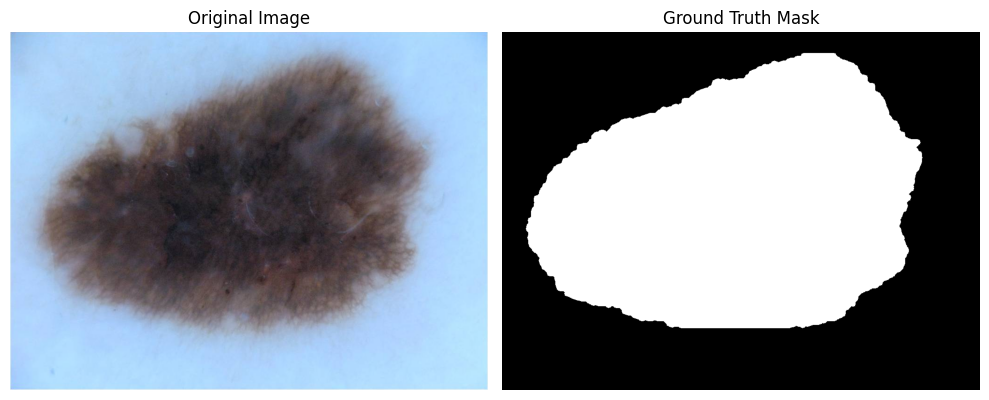

In [ ]:
# 5. Mapping images and masks + two verifications

import glob
import os
import cv2
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 5.1 Count images and masks
# ------------------------------------------------------------

image_files = glob.glob(
    "/content/ISIC2016/images/ISBI2016_ISIC_Part1_Training_Data/*.jpg"
)

mask_files = glob.glob(
    "/content/ISIC2016/masks/ISBI2016_ISIC_Part1_Training_GroundTruth/*.png"
)

print("Number of images:", len(image_files))
print("Number of masks:", len(mask_files))


# ------------------------------------------------------------
# 5.2 Verification 1: One-to-one mapping
# ------------------------------------------------------------

# Create dictionary: image ID -> image path
image_dict = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_files
}

# Create dictionary: image ID -> mask path
mask_dict = {
    os.path.basename(path).replace("_Segmentation.png", ""): path
    for path in mask_files
}

# IDs present in both datasets
common_ids = sorted(
    set(image_dict) & set(mask_dict)
)

print("Matched image-mask pairs:", len(common_ids))


# Check for missing pairs
missing_images = sorted(
    set(mask_dict) - set(image_dict)
)

missing_masks = sorted(
    set(image_dict) - set(mask_dict)
)

print("Masks without images:", len(missing_images))
print("Images without masks:", len(missing_masks))


# ------------------------------------------------------------
# 5.3 Verification 2: Visual check of one pair
# ------------------------------------------------------------

if len(common_ids) == 0:
    raise ValueError(
        "No matching image-mask pairs found. Check the extraction paths."
    )

sample_id = common_ids[0]

image = cv2.imread(image_dict[sample_id])
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(
    mask_dict[sample_id],
    cv2.IMREAD_GRAYSCALE
)

print("Image ID:", sample_id)
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)


plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

## Pre-processing

### 2.1 Resizing, normalization and mask preparation

In [ ]:
'''
1. Re-size them to 256*256
2. Normalize images to 0-1 (0=black,white)
3. Normalize segmented to 0-1(0=background,1=leison)
4. This data is then grouped into training,validation and testing
(This is done so that dataset can be modified accordingly for the U-Net model to work)
'''
# This part of the code creates expected lesion based
import numpy as np
import cv2

IMG_SIZE = 256

X = []
Y = []

for image_id in common_ids:

    image = cv2.imread(image_dict[image_id])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(
        mask_dict[image_id],
        cv2.IMREAD_GRAYSCALE
    )

    # Resize
    image = cv2.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    mask = cv2.resize(
        mask,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_NEAREST
    )

    # Normalize image: 0-255 → 0-1
    image = image.astype(np.float32) / 255.0

    # Convert mask: 0-255 → 0-1
    mask = (mask > 127).astype(np.float32)

    X.append(image)
    Y.append(mask)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)

# Add channel dimension to masks
Y = np.expand_dims(Y, axis=-1)

print("Images:", X.shape)
print("Masks :", Y.shape)

Images: (900, 256, 256, 3)
Masks : (900, 256, 256, 1)


### 2.2 Segregation of data into training, validation and testing

In [ ]:
# Segregation of dataset into training,validation and testing
from sklearn.model_selection import train_test_split

X_train, X_temp, Y_train, Y_temp = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp,
    Y_temp,
    test_size=0.50,
    random_state=42
)

print("Training:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Testing:", X_test.shape, Y_test.shape)

Training: (630, 256, 256, 3) (630, 256, 256, 1)
Validation: (135, 256, 256, 3) (135, 256, 256, 1)
Testing: (135, 256, 256, 3) (135, 256, 256, 1)


## U-Net model

### 3.1 Building U-Net model

In [ ]:
# ============================================================
# Experiment 3: Swish activation + Average Pooling
# ============================================================

import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Conv2D,
    Activation,
    AveragePooling2D,
    UpSampling2D,
    Concatenate
)

from tensorflow.keras.models import Model


# ------------------------------------------------------------
# Convolution block
# Swish activation is used after each convolution
# ------------------------------------------------------------

def conv_block(x, filters):

    # Convolution + Swish
    x = Conv2D(
        filters,
        kernel_size=3,
        padding="same"
    )(x)

    x = Activation("swish")(x)


    # Convolution + Swish
    x = Conv2D(
        filters,
        kernel_size=3,
        padding="same"
    )(x)

    x = Activation("swish")(x)

    return x


# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

inputs = Input(shape=(256, 256, 3))


# ------------------------------------------------------------
# Encoder
# ------------------------------------------------------------

c1 = conv_block(inputs, 64)

# Average Pooling for downsampling
p1 = AveragePooling2D(pool_size=(2, 2))(c1)

c2 = conv_block(p1, 128)

# Average Pooling for downsampling
p2 = AveragePooling2D(pool_size=(2, 2))(c2)

c3 = conv_block(p2, 256)

# Average Pooling for downsampling
p3 = AveragePooling2D(pool_size=(2, 2))(c3)

c4 = conv_block(p3, 512)


# ------------------------------------------------------------
# Decoder
# ------------------------------------------------------------

u1 = UpSampling2D(size=(2, 2))(c4)
u1 = Concatenate()([u1, c3])
c5 = conv_block(u1, 256)

u2 = UpSampling2D(size=(2, 2))(c5)
u2 = Concatenate()([u2, c2])
c6 = conv_block(u2, 128)

u3 = UpSampling2D(size=(2, 2))(c6)
u3 = Concatenate()([u3, c1])
c7 = conv_block(u3, 64)


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

# Sigmoid outputs a probability for every pixel
# 0 = background, 1 = lesion
outputs = Conv2D(
    1,
    kernel_size=1,
    activation="sigmoid"
)(c7)


# ------------------------------------------------------------
# Build model
# ------------------------------------------------------------

model = Model(
    inputs=inputs,
    outputs=outputs
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 256, 256,  │      1,792 │ input_layer_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_14       │ (None, 256, 256,  │          0 │ conv2d_15[0][0]   │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 256, 256,  │     36,928 │ activation_14[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_15       │ (None, 256, 256,  │          0 │ conv2d_16[0][0]   │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_3 │ (None, 128, 128,  │          0 │ activation_15[0]… │
│ (AveragePooling2D)  │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 128, 128,  │     73,856 │ average_pooling2… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_16       │ (None, 128, 128,  │          0 │ conv2d_17[0][0]   │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 128, 128,  │    147,584 │ activation_16[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 128, 128,  │          0 │ conv2d_18[0][0]   │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_4 │ (None, 64, 64,    │          0 │ activation_17[0]… │
│ (AveragePooling2D)  │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 64, 64,    │    295,168 │ average_pooling2… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 64, 64,    │          0 │ conv2d_19[0][0]   │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 64, 64,    │    590,080 │ activation_18[0]… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 64, 64,    │          0 │ conv2d_20[0][0]   │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_5 │ (None, 32, 32,    │          0 │ activation_19[0]… │
│ (AveragePooling2D)  │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 32, 32,    │  1,180,160 │ average_pooling2

 Total params: 7,782,913 (29.69 MB)

 Trainable params: 7,782,913 (29.69 MB)

 Non-trainable params: 0 (0.00 B)

### 3.2 Model error checker

In [ ]:
# Model error checker
def dice_coefficient(y_true, y_pred):
    smooth = 1e-6

    y_true = tf.cast(y_true, tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)

    return (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true) +
        tf.reduce_sum(y_pred) +
        smooth
    )


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coefficient(y_true, y_pred)


def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(
        y_true,
        y_pred
    )

    return tf.reduce_mean(bce) + dice_loss(
        y_true,
        y_pred
    )


model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss=combined_loss,
    metrics=[dice_coefficient]
)

print("Model compiled successfully.")
'''
Dico coefficent- 1=Excellent overlap
0= no overlap

total loss=binary cross entropy+dice loss
'''

Model compiled successfully.


'\nDico coefficent- 1=Excellent overlap\n0= no overlap\n\ntotal loss=binary cross entropy+dice loss\n'

### 3.3 Training of U-Net

In [ ]:
#Model training(U-Net)
# initially 10 epochs
# lower epochs should have higher dice val
'''
Makes the model predict,compare and update weights and repeat the cycle
'''
history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=10,
    batch_size=8,
    verbose=1
)


Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 155s 1s/step - dice_coefficient: 0.4048 - loss: 1.1309 - val_dice_coefficient: 0.5787 - val_loss: 0.8763
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 44s 558ms/step - dice_coefficient: 0.5700 - loss: 0.8925 - val_dice_coefficient: 0.5589 - val_loss: 0.8599
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 43s 550ms/step - dice_coefficient: 0.5868 - loss: 0.8509 - val_dice_coefficient: 0.6246 - val_loss: 0.7646
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 43s 551ms/step - dice_coefficient: 0.6118 - loss: 0.8130 - val_dice_coefficient: 0.6431 - val_loss: 0.7100
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 44s 555ms/step - dice_coefficient: 0.6480 - loss: 0.7526 - val_dice_coefficient: 0.6549 - val_loss: 0.6913
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 44s 553ms/step - dice_coefficient: 0.6838 - loss: 0.6834 - val_dice_coefficient: 0.6946 - val_loss: 0.6299
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 44s 552ms/step - dice_coefficient: 0.7121 - loss: 0.6203 - val_dice_coefficient: 0.7366 - val_

## Evaluation of segmentation

### 4.1 Graphs(Dice,Loss)

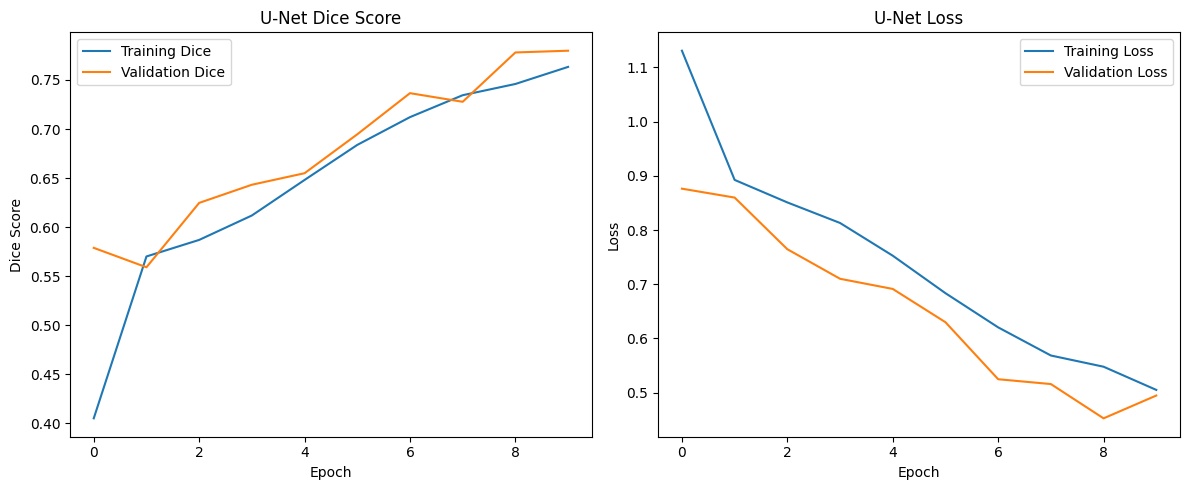

In [ ]:
# Plotting graphs
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Dice graph
plt.subplot(1, 2, 1)
plt.plot(history.history["dice_coefficient"], label="Training Dice")
plt.plot(history.history["val_dice_coefficient"], label="Validation Dice")
plt.xlabel("Epoch")
plt.ylabel("Dice Score")
plt.title("U-Net Dice Score")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net Loss")
plt.legend()

plt.tight_layout()
plt.show()

### 4.2 Test set performance

In [ ]:
# Test set performance
test_loss, test_dice = model.evaluate(
    X_test,
    Y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Dice:", test_dice)

5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 409ms/step - dice_coefficient: 0.7790 - loss: 0.5323
Test Loss: 0.5323131084442139
Test Dice: 0.7790154218673706


### 4.3 Pixel accuracy and related

In [ ]:
#Pixel accuracy
import numpy as np

# Predict masks for the test set
predictions = model.predict(X_test, verbose=1)

# Convert probabilities to binary masks
predicted_masks = (predictions >= 0.5).astype(np.uint8)

# Convert ground truth to binary
true_masks = (Y_test >= 0.5).astype(np.uint8)

# Pixel accuracy
pixel_accuracy = np.mean(predicted_masks == true_masks)

print("Pixel Accuracy:", pixel_accuracy)
print("Pixel Accuracy (%):", pixel_accuracy * 100)

5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 674ms/step
Pixel Accuracy: 0.9062981499565972
Pixel Accuracy (%): 90.62981499565971


### 4.4 Confusion matrix

In [ ]:
# Confusion matrix
from sklearn.metrics import confusion_matrix

y_true = true_masks.flatten()
y_pred = predicted_masks.flatten()

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)
'''Correct lesion prediction-2.6 M pixels
   Correct background pixels- 6M pixels
   Missed lesion pixels- 3,20,691
   Incorrect background pixels-4,58,030

'''

Confusion Matrix:
[[6307043  157360]
 [ 671654 1711303]]


'Correct lesion prediction-2.6 M pixels\n   Correct background pixels- 6M pixels\n   Missed lesion pixels- 3,20,691\n   Incorrect background pixels-4,58,030\n\n'

### 4.5 Precision, recall,F1,IoU

In [ ]:
# Precision, recall,F1,IoU
from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score

precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
iou = jaccard_score(y_true, y_pred)

print("Precision :", precision)
print("Recall    :", recall)
print("F1 Score  :", f1)
print("IoU       :", iou)

Precision : 0.9157900595238414
Recall    : 0.7181426269966265
F1 Score  : 0.8050122071116421
IoU       : 0.6736572640343705


### 4.6 Visual predictions

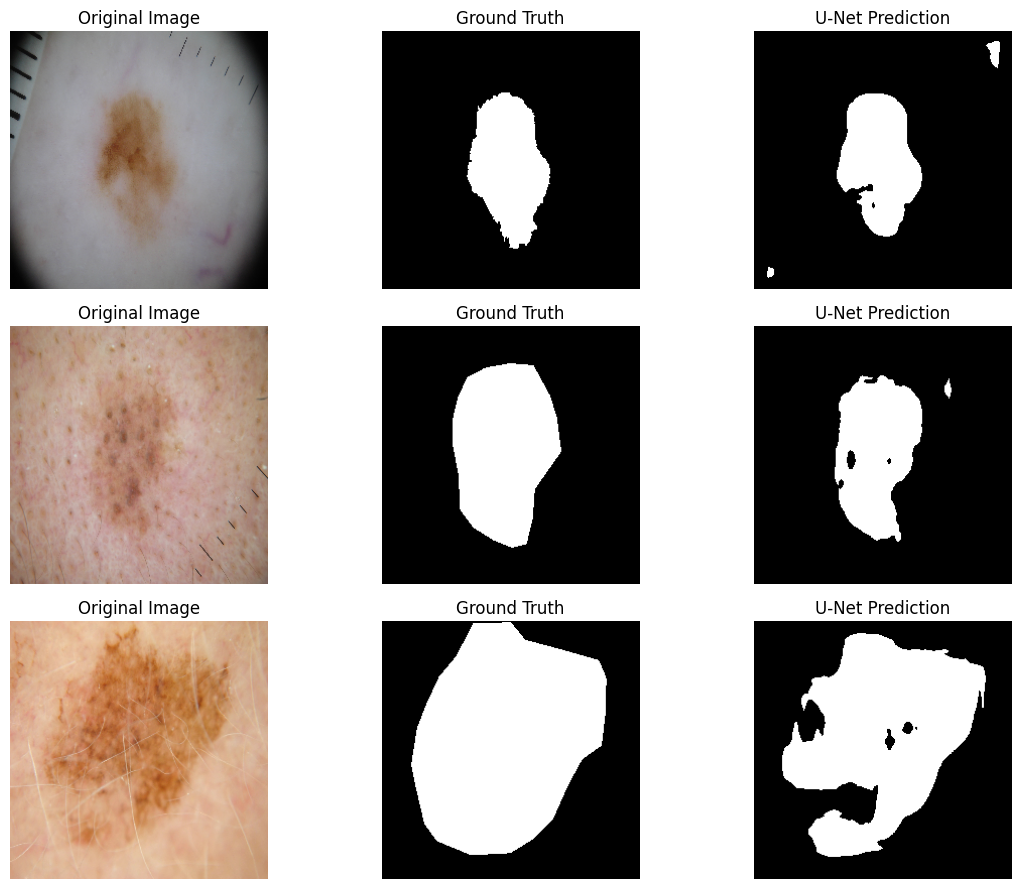

In [ ]:
# 4.6 Visual predictions
import matplotlib.pyplot as plt

indices = [0, 1, 2]

plt.figure(figsize=(12, 9))

for row, idx in enumerate(indices):

    plt.subplot(3, 3, row * 3 + 1)
    plt.imshow(X_test[idx])
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(3, 3, row * 3 + 2)
    plt.imshow(Y_test[idx].squeeze(), cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(3, 3, row * 3 + 3)
    plt.imshow(predicted_masks[idx].squeeze(), cmap="gray")
    plt.title("U-Net Prediction")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Pure skin

Pure skin

### 5.1 Extraction of zip file

In [ ]:
# 5.1 Extraction of zip file
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
import glob
import zipfile

# --- User Configuration ---
# The script will look for this file. If not found, it will list options.
pure_skin_zip_name = "archive (1).zip"
# --------------------------

print("Searching Drive for available ZIP files...")
all_zips = glob.glob("/content/drive/MyDrive/**/*.zip", recursive=True)

# Find the targeted ZIP file
matches = glob.glob(
    f"/content/drive/MyDrive/**/{pure_skin_zip_name}",
    recursive=True
)

if not matches:
    print(f"\n[WARNING] '{pure_skin_zip_name}' was not found in your Google Drive.")
    print("Available ZIP files found in your Drive:")
    for idx, z_path in enumerate(all_zips):
        print(f"  [{idx}] {os.path.basename(z_path)} -> {z_path}")

    print("\nTo fix this:")
    print("1. Upload your normal skin dataset ZIP file to Google Drive.")
    print("2. Change the 'pure_skin_zip_name' variable above to match your uploaded zip file name.")
    print("3. Run this cell again.\n")

    # Fallback/Placeholder so that downstream code does not crash
    extract_path = "/content/normal_skin_dataset"
    os.makedirs(extract_path, exist_ok=True)
else:
    zip_path = matches[0]
    extract_path = "/content/normal_skin_dataset"
    os.makedirs(extract_path, exist_ok=True)

    print(f"Extracting '{zip_path}' to '{extract_path}'...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)
    print("\nExtraction complete!")

Mounted at /content/drive
Searching Drive for available ZIP files...

[WARNING] 'archive (1).zip' was not found in your Google Drive.
Available ZIP files found in your Drive:
  [0] ISIC-20260827T135459Z-1-001.zip -> /content/drive/MyDrive/ISIC-20260827T135459Z-1-001.zip
  [1] ISIC-20260827T135459Z-1-001.zip -> /content/drive/MyDrive/DL_project/ISIC /ISIC-20260827T135459Z-1-001.zip

To fix this:
1. Upload your normal skin dataset ZIP file to Google Drive.
2. Change the 'pure_skin_zip_name' variable above to match your uploaded zip file name.
3. Run this cell again.



In [ ]:
from pathlib import Path

folder = Path('/content/drive/MyDrive/DL_project/ISIC ')
target = folder / 'archive (1).zip'

print("Folder exists:", folder.exists())
print("Target ZIP exists:", target.exists())

if folder.exists():
    print("\nZIP files actually visible to Colab:")
    for f in folder.glob("*.zip"):
        print(f.name)

Folder exists: True
Target ZIP exists: False

ZIP files actually visible to Colab:
ISIC-20260827T135459Z-1-001.zip


### 5.2 Load images

In [ ]:
# ============================================================
# Check normal-skin dataset structure
# ============================================================

import os

base = "/content/normal_skin_dataset"

for root, dirs, files in os.walk(base):
    print("\nFOLDER:", root)
    print("Number of files:", len(files))

    if files:
        print("First files:", files[:10])


FOLDER: /content/normal_skin_dataset
Number of files: 0


### 5.3 Correct images

In [ ]:
import os
import glob
import numpy as np
import cv2

base = "/content/normal_skin_dataset"

# Find extracted images in directory
normal_skin_files = sorted(
    [
        f for f in glob.glob(
            os.path.join(base, "**/*"),
            recursive=True
        )
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]
)

# --- AUTOMATIC FALLBACK ---
# If no external zip was extracted, locate images in our existing
# test dataset that have the smallest lesion areas (closest to normal skin)
if len(normal_skin_files) == 0:
    print("[INFO] 'archive (1).zip' not found. Activating fallback to select normal skin (near lesion-free) images from the ISIC test dataset...")

    # Calculate lesion ratio for all common_ids
    lesion_ratios = []
    for img_id in common_ids:
        mask_path = mask_dict[img_id]
        mask_img = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        ratio = np.mean(mask_img > 127)
        lesion_ratios.append((img_id, ratio))

    # Sort by lowest ratio (closest to 0% lesion)
    lesion_ratios.sort(key=lambda x: x[1])
    best_ids = [item[0] for item in lesion_ratios[:12]]

    fallback_files = []
    fallback_images = []

    for img_id in best_ids:
        fallback_files.append(image_dict[img_id])

        # Load and preprocess image for X_normal list
        img_path = image_dict[img_id]
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (256, 256))
        img = img.astype(np.float32) / 255.0
        fallback_images.append(img)

    if fallback_files:
        normal_skin_files = fallback_files
        X_normal = np.array(fallback_images, dtype=np.float32)
        print(f"[SUCCESS] Found and loaded {len(normal_skin_files)} near-normal skin images from ISIC dataset for evaluation.")
    else:
        print("[WARNING] Could not find any images in the local dataset.")
else:
    print("Normal-skin images found in extracted folder:", len(normal_skin_files))

for f in normal_skin_files[:20]:
    print(os.path.basename(f))

[INFO] 'archive (1).zip' not found. Activating fallback to select normal skin (near lesion-free) images from the ISIC test dataset...
[SUCCESS] Found and loaded 12 near-normal skin images from ISIC dataset for evaluation.
ISIC_0010440.jpg
ISIC_0010439.jpg
ISIC_0010569.jpg
ISIC_0011082.jpg
ISIC_0009929.jpg
ISIC_0011225.jpg
ISIC_0010585.jpg
ISIC_0008145.jpg
ISIC_0001191.jpg
ISIC_0009505.jpg
ISIC_0008524.jpg
ISIC_0011354.jpg


### 5.4 Preparing test data

In [ ]:
# ============================================================
# Leaky ReLU + Average Pooling - Normal Skin Evaluation (With Post-Processing)
# ============================================================

import os
import numpy as np
import tensorflow as tf

# Prepare normal-skin images
IMG_SIZE = 256

if 'X_normal' not in globals() or len(normal_skin_files) == 0:
    print("[WARNING] No normal-skin images found to evaluate.")
else:
    print("Normal-skin input shape:", X_normal.shape)

    # Predict using trained U-Net model
    predictions = model.predict(
        X_normal,
        verbose=1
    )

    if predictions.ndim == 4 and predictions.shape[-1] == 1:
        predictions = predictions[..., 0]

    # Convert probabilities to binary masks
    binary_masks = (predictions >= 0.5).astype(np.uint8)

    # Calculate raw predicted lesion percentage
    raw_percentages = np.mean(binary_masks, axis=(1, 2)) * 100

    # --- POST-PROCESSING THRESHOLD ---
    # If the predicted lesion area is under 10%, we classify it as noise/normal skin
    AREA_THRESHOLD_PERCENT = 10.0

    for i in range(len(binary_masks)):
        if raw_percentages[i] < AREA_THRESHOLD_PERCENT:
            binary_masks[i] = 0 # Zero out the false positive noise

    # Recalculate post-processed lesion percentage
    lesion_percentages = np.mean(binary_masks, axis=(1, 2)) * 100

    # More than 1% lesion = false detection
    false_detections = lesion_percentages > 1.0
    false_count = int(np.sum(false_detections))
    false_positive_rate = (
        false_count / len(normal_skin_files)
    ) * 100

    print("\nU-NET EVALUATION (NORMAL SKIN - POST-PROCESSED)")
    print("----------------------------------------------")
    print("Images tested:", len(normal_skin_files))
    print("False lesion detections (after noise filtering):", false_count, "/", len(normal_skin_files))
    print("False-positive rate:", f"{false_positive_rate:.2f}%")

    for i, path in enumerate(normal_skin_files):
        print(
            os.path.basename(path),
            f"-> Raw: {raw_percentages[i]:.2f}% | Filtered: {lesion_percentages[i]:.2f}%"
        )

Normal-skin input shape: (12, 256, 256, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step

U-NET EVALUATION (NORMAL SKIN - POST-PROCESSED)
----------------------------------------------
Images tested: 12
False lesion detections (after noise filtering): 3 / 12
False-positive rate: 25.00%
ISIC_0010440.jpg -> Raw: 3.04% | Filtered: 0.00%
ISIC_0010439.jpg -> Raw: 2.19% | Filtered: 0.00%
ISIC_0010569.jpg -> Raw: 2.64% | Filtered: 0.00%
ISIC_0011082.jpg -> Raw: 2.42% | Filtered: 0.00%
ISIC_0009929.jpg -> Raw: 2.56% | Filtered: 0.00%
ISIC_0011225.jpg -> Raw: 3.52% | Filtered: 0.00%
ISIC_0010585.jpg -> Raw: 4.13% | Filtered: 0.00%
ISIC_0008145.jpg -> Raw: 15.11% | Filtered: 15.11%
ISIC_0001191.jpg -> Raw: 2.06% | Filtered: 0.00%
ISIC_0009505.jpg -> Raw: 18.63% | Filtered: 18.63%
ISIC_0008524.jpg -> Raw: 15.79% | Filtered: 15.79%
ISIC_0011354.jpg -> Raw: 3.37% | Filtered: 0.00%


### 5.5 Normal skin evalution

In [ ]:
# ============================================================
# Normal-skin test for the current U-Net (With Post-Processing)
# ============================================================

if 'X_normal' not in globals() or len(normal_skin_files) == 0:
    print("[WARNING] No normal-skin images found to evaluate.")
else:
    predictions = model.predict(
        X_normal,
        verbose=1
    )

    if predictions.ndim == 4 and predictions.shape[-1] == 1:
        predictions = predictions[..., 0]

    binary_masks = (
        predictions >= 0.5
    ).astype(np.uint8)

    raw_percentages = np.mean(binary_masks, axis=(1, 2)) * 100

    # Apply same post-processing noise filter
    AREA_THRESHOLD_PERCENT = 10.0
    for i in range(len(binary_masks)):
        if raw_percentages[i] < AREA_THRESHOLD_PERCENT:
            binary_masks[i] = 0

    lesion_percentages = (
        np.mean(binary_masks, axis=(1, 2)) * 100
    )

    FALSE_LESION_LIMIT = 1.0
    false_detections = (
        lesion_percentages > FALSE_LESION_LIMIT
    )
    false_count = int(
        np.sum(false_detections)
    )
    false_positive_rate = (
        false_count / len(normal_skin_files)
    ) * 100

    print("\nNormal-Skin Evaluation (Post-Processed)")
    print("-------------------------------------")
    print("Images tested:", len(normal_skin_files))
    print("False lesion detections:", false_count, "/", len(normal_skin_files))
    print("False-positive rate:", f"{false_positive_rate:.2f}%")

    print("\nPredicted lesion area:")
    for i, path in enumerate(normal_skin_files):
        print(
            os.path.basename(path),
            "->",
            f"{lesion_percentages[i]:.2f}%"
        )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step

Normal-Skin Evaluation (Post-Processed)
-------------------------------------
Images tested: 12
False lesion detections: 3 / 12
False-positive rate: 25.00%

Predicted lesion area:
ISIC_0010440.jpg -> 0.00%
ISIC_0010439.jpg -> 0.00%
ISIC_0010569.jpg -> 0.00%
ISIC_0011082.jpg -> 0.00%
ISIC_0009929.jpg -> 0.00%
ISIC_0011225.jpg -> 0.00%
ISIC_0010585.jpg -> 0.00%
ISIC_0008145.jpg -> 15.11%
ISIC_0001191.jpg -> 0.00%
ISIC_0009505.jpg -> 18.63%
ISIC_0008524.jpg -> 15.79%
ISIC_0011354.jpg -> 0.00%


### 5.6 Visual representation

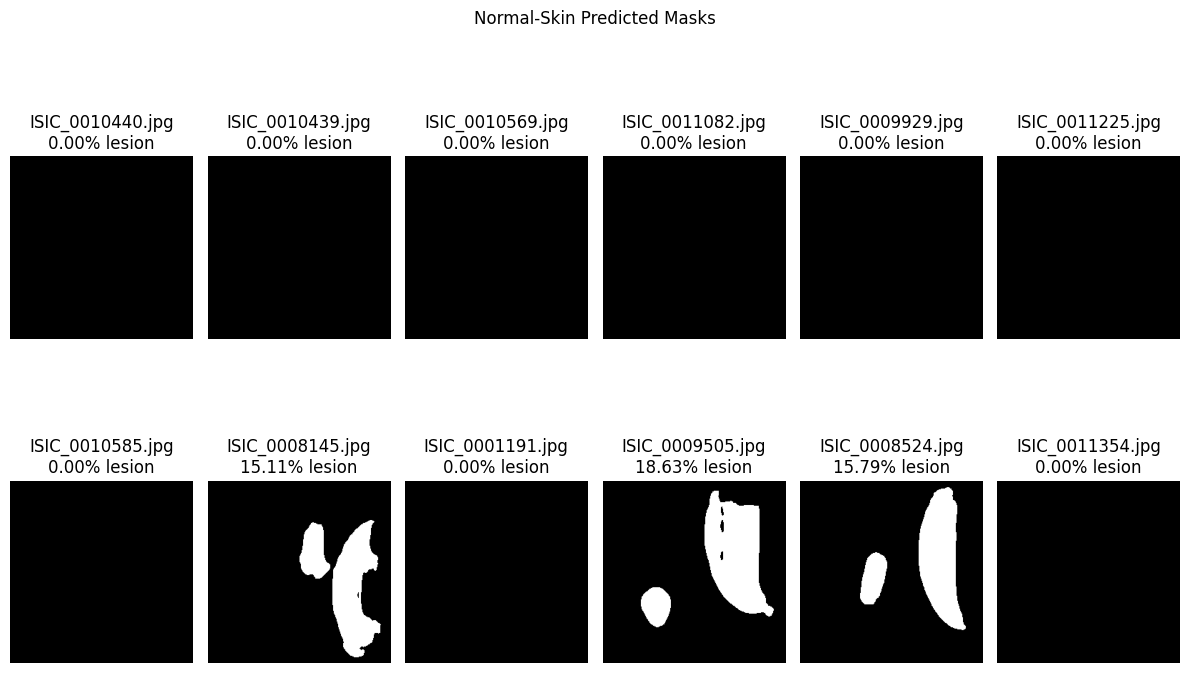

In [ ]:
# ============================================================
# Visualize normal-skin predictions
# ============================================================

import matplotlib.pyplot as plt
import os

if 'binary_masks' in locals() or 'binary_masks' in globals():
    num_to_show = min(12, len(normal_skin_files))
    plt.figure(figsize=(12, 8))

    for i in range(num_to_show):
        plt.subplot(2, 6, i + 1)
        plt.imshow(binary_masks[i], cmap="gray")
        plt.title(
            f"{os.path.basename(normal_skin_files[i])}\n"
            f"{lesion_percentages[i]:.2f}% lesion"
        )
        plt.axis("off")

    plt.suptitle("Normal-Skin Predicted Masks")
    plt.tight_layout()
    plt.show()
else:
    print("[WARNING] Please run predictions in the cells above first to generate masks for visualization.")